# 5-day test of the patch-level MEGAN branch run (exact split, option 1)

Technical go/no-go check before the production branch runs of option 1 in `analysis/MEGAN_ATTRIBUTION.md` (exact LMDI split of the MEGAN emission change). No science result.

**Run tested.** A 5-day **branch** of CTRL_PD (`NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023`, old chain) at 2005-01-01, with the parent's namelists and output, plus one extra CLM history tape: 72 MEGAN fields (emission, ε and γ's of isoprene + 7 monoterpenes, and the driver fields for the offline replay) **per patch, every 30-min time step, instantaneous**. Case `…-test-meganpatch-5day-20261029`, job 1784026; case script `cases-scripts/tests/13a-NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-meganpatch-5day.sh` (now the template for the production branches, with MEGAN-only output).

| # | Question | Why it matters | Section |
|---|---|---|---|
| 1 | Does the branch reproduce CTRL_PD **bit for bit**? | Only then is it the same run (not another ensemble member), so the split is a split of the main runs | §1 |
| 2 | Is the output right (fields, patch dimension, time steps)? | A wrong setting found after the production runs means redoing them | §2 |
| 3 | Is `GAMMA` exactly the product of the γ's in each patch and step, and `MEG` = `EPS` × `GAMMA` × constant? | The exact (LMDI) split relies on it | §3 |
| 4 | File size per day | Disk needed, and how fast the reduction must keep up | §4 |
| 5 | Slowdown from writing every step | Core-hours and wall time of the production runs | §5 |


In [1]:
import glob, gzip, os, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from netCDF4 import Dataset

PARENT = "NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023"
CASE = "NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-test-meganpatch-5day-20261029"
COMPOUNDS = ["isoprene", "pinene_a", "carene_3", "pinene_b", "myrcene", "limonene", "ocimene_t_b", "sabinene"]
DRIVERS = ["TV", "TV24", "TV240", "ELAI", "LAI240", "FSUN", "FSUN24", "FSUN240", "FSD24", "FSD240", "FSI24",
           "FSI240", "PAR_sun", "PAR24_sun", "PAR240_sun", "PAR_shade", "PAR24_shade", "PAR240_shade",
           "TOPT", "EOPT", "ALPHA", "currentPatch"]
TAPE2 = ([f"MEG_{c}" for c in COMPOUNDS] + ["GAMMAL", "GAMMAC_isoprene"]
         + [f"{f}_{c}" for c in COMPOUNDS for f in ["EPS", "GAMMA", "GAMMAP", "GAMMAT", "GAMMAA"]] + DRIVERS)
NIRD = "/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive"
ARCHIVE, WORK = "/cluster/work/users/adelez/archive", "/cluster/work/users/adelez/noresm"
CASES_DIR = Path.home() / "cases/BRL_FRST_XPSN"
OUT = Path("megan_patch_branch_5day_test_outputs"); OUT.mkdir(exist_ok=True)


def hist_files(case, comp, tape):
    """History files of `case`: archive first, then run directory (not archived yet)."""
    sub = {"cam": "atm", "clm2": "lnd"}[comp]
    for d in (f"{ARCHIVE}/{case}/{sub}/hist", f"{WORK}/{case}/run"):
        files = sorted(glob.glob(f"{d}/{case}.{comp}.{tape}.*.nc"))
        if files:
            return files
    return []


cam_b = hist_files(CASE, "cam", "h1")
cam_p = sorted(glob.glob(f"{NIRD}/{PARENT}/atm/hist/{PARENT}.cam.h1.2005-01-0[1-7]-00000.nc"))
clm_b = hist_files(CASE, "clm2", "h1")
print(f"CAM h1: branch {len(cam_b)} files, parent {len(cam_p)} files; CLM tape 2: {len(clm_b)} files")


CAM h1: branch 5 files, parent 7 files; CLM tape 2: 5 files


## §1 Bit-identity with the parent

Compare the 30-min instantaneous CAM `SFISOP` and `SFMTERP` (CAM h1, written by both runs) at every common time step, matched by the **time value**: file names differ (the branch's daily files start at 00:30, `-01800`; the parent's at 00:00, `-00000`). The test is exact (`np.array_equal`, no tolerance). These fluxes depend on the land state (MEGAN) and on the atmosphere (temperature, light), so a difference anywhere in the coupled model shows up in them within a few steps.


In [2]:
FIELDS = ["SFISOP", "SFMTERP"]

def load_cam(files):
    t, d = [], {v: [] for v in FIELDS}
    for f in files:
        with Dataset(f) as n:
            t.append(n["time"][:])
            for v in FIELDS:
                d[v].append(np.asarray(n[v][:]))
    return np.concatenate(t), {v: np.concatenate(x) for v, x in d.items()}

tb, b = load_cam(cam_b)
tp, p = load_cam(cam_p)
common = np.intersect1d(tb, tp)
ib, ip = np.searchsorted(tb, common), np.searchsorted(tp, common)
rows, series = [], {}
for v in FIELDS:
    x, y = b[v][ib], p[v][ip]
    diff = np.abs(x.astype(np.float64) - y.astype(np.float64)).reshape(len(common), -1).max(axis=1)
    rows.append({"field": v, "common 30-min steps": len(common), "first step (days)": common[0],
                 "last step (days)": common[-1], "steps not identical": int((diff > 0).sum()),
                 "max |diff|": diff.max(), "max |value|": np.abs(y).max(), "bit-identical": bool(np.array_equal(x, y))})
    series[v] = (x.reshape(len(common), -1).mean(axis=1), y.reshape(len(common), -1).mean(axis=1), diff)
identity = pd.DataFrame(rows)
identity.to_csv(OUT / "s1_identity.csv", index=False)
identity


,field,common 30-min steps,first step (days),last step (days),steps not identical,max |diff|,max |value|,bit-identical
0,SFISOP,240,1825.020833,1830.0,0,0.0,9.370941e-09,True
1,SFMTERP,240,1825.020833,1830.0,0,0.0,1.331373e-09,True


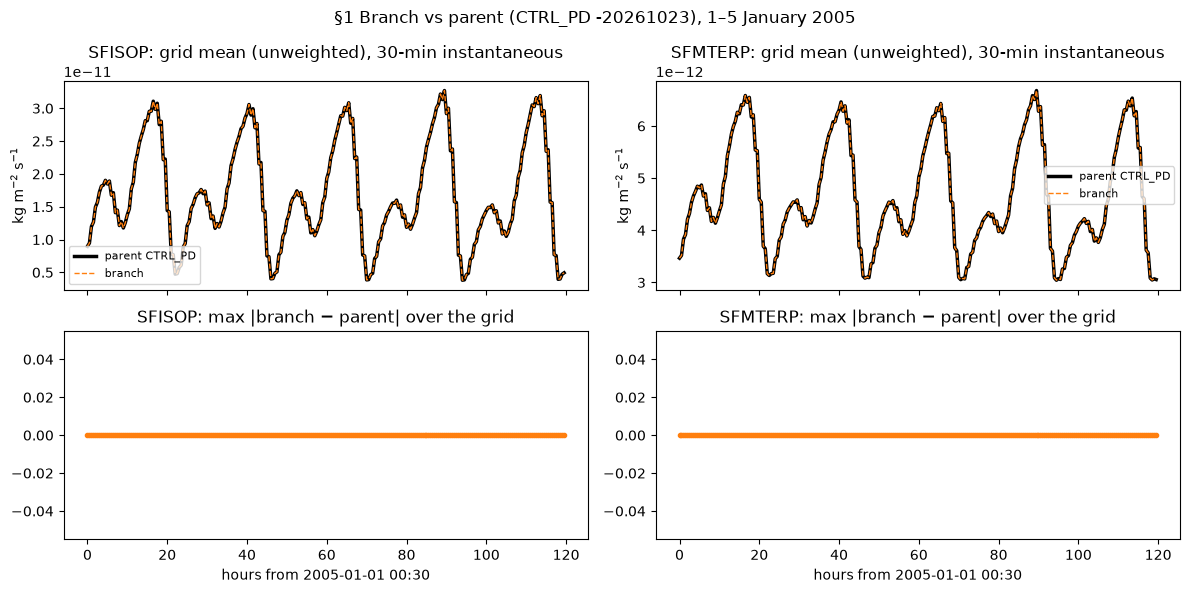

In [3]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
hours = (common - common[0]) * 24
for j, v in enumerate(FIELDS):
    xb, xp, diff = series[v]
    axes[0, j].plot(hours, xp, color="k", lw=2.5, label="parent CTRL_PD")
    axes[0, j].plot(hours, xb, color="#DE7A3A", lw=1, ls="--", label="branch")
    axes[0, j].set_title(f"{v}: grid mean (unweighted), 30-min instantaneous")
    axes[0, j].set_ylabel("kg m$^{-2}$ s$^{-1}$")
    axes[0, j].legend(fontsize=8)
    axes[1, j].plot(hours, diff, marker=".", ls="none", color="#DE7A3A")
    axes[1, j].set_title(f"{v}: max |branch − parent| over the grid")
    axes[1, j].set_xlabel("hours from 2005-01-01 00:30")
fig.suptitle("§1 Branch vs parent (CTRL_PD -20261023), 1–5 January 2005")
fig.tight_layout()
fig.savefig(OUT / "s1_identity_timeseries.png", dpi=150)


## §2 Output of the patch-level tape

Expected: one file per day with 48 records (30-min steps), the patch dimension `pft` (65,485 patches in CTRL_PD), and all 72 requested fields.


In [4]:
rows = []
for f in clm_b:
    with Dataset(f) as n:
        rows.append({"file": os.path.basename(f).split(".clm2.")[1], "records": len(n["time"]),
                     "patches": len(n.dimensions["pft"]) if "pft" in n.dimensions else None,
                     "missing fields": [v for v in TAPE2 if v not in n.variables]})
output = pd.DataFrame(rows)
output.to_csv(OUT / "s2_output.csv", index=False)
print(f"{len(TAPE2)} fields requested")
output


72 fields requested


,file,records,patches,missing fields
0,h1.2005-01-01-01800.nc,48,65485,[]
1,h1.2005-01-02-01800.nc,48,65485,[]
2,h1.2005-01-03-01800.nc,48,65485,[]
3,h1.2005-01-04-01800.nc,48,65485,[]
4,h1.2005-01-05-01800.nc,48,65485,[]


## §3 Exact product per patch and time step

In CLM (`VOCEmission` in `model/SourceMods/src.clm/VOCEmissionMod.F90`): `GAMMA = GAMMAL · GAMMAA · GAMMAP · GAMMAT (· GAMMAC for isoprene)` (γSM = 1), and `MEG = EPS · GAMMA · unit factor`. Checked where `GAMMA > 0`, over all patches and steps of the 5 days. The LMDI split relies on this holding exactly at this level.


In [5]:
acc = {c: {"n": 0, "max_rel_product": 0.0, "ratios": []} for c in COMPOUNDS}
for f in clm_b:
    with Dataset(f) as n:
        gl = np.ma.filled(n["GAMMAL"][:], np.nan)
        for c in COMPOUNDS:
            g = np.ma.filled(n[f"GAMMA_{c}"][:], np.nan)
            prod = gl * np.ma.filled(n[f"GAMMAT_{c}"][:], np.nan) * np.ma.filled(n[f"GAMMAP_{c}"][:], np.nan) \
                   * np.ma.filled(n[f"GAMMAA_{c}"][:], np.nan)
            if c == "isoprene":
                prod = prod * np.ma.filled(n["GAMMAC_isoprene"][:], np.nan)
            ok = np.isfinite(g) & (g > 0)
            rel = np.abs(prod[ok] - g[ok]) / g[ok]
            acc[c]["n"] += int(ok.sum())
            acc[c]["max_rel_product"] = max(acc[c]["max_rel_product"], float(np.nanmax(rel)))
            ratio = np.ma.filled(n[f"MEG_{c}"][:], np.nan)[ok] / (np.ma.filled(n[f"EPS_{c}"][:], np.nan)[ok] * g[ok])
            acc[c]["ratios"].append(ratio[np.isfinite(ratio) & (ratio > 0)])
rows = []
for c, a in acc.items():
    r = np.concatenate(a["ratios"])
    rows.append({"compound": c, "values (GAMMA > 0)": a["n"],
                 "max rel |product − GAMMA|": a["max_rel_product"],
                 "MEG / (EPS·GAMMA)": r.mean(), "spread of that ratio": (r.max() - r.min()) / r.mean()})
product = pd.DataFrame(rows)
product.to_csv(OUT / "s3_product.csv", index=False)
product


,compound,values (GAMMA > 0),max rel |product − GAMMA|,MEG / (EPS·GAMMA),spread of that ratio
0,isoprene,2808541,6.447151e-16,2.777778e-13,5.452607e-16
1,pinene_a,3027426,4.741835e-16,2.777778e-13,5.452607e-16
2,carene_3,3027426,5.113961e-16,2.777778e-13,5.452607e-16
3,pinene_b,3027426,5.113961e-16,2.777778e-13,5.452607e-16
4,myrcene,3027426,4.741835e-16,2.777778e-13,5.452607e-16
5,limonene,3027426,5.113961e-16,2.777778e-13,5.452607e-16
6,ocimene_t_b,3027426,5.113961e-16,2.777778e-13,5.452607e-16
7,sabinene,3027426,4.741835e-16,2.777778e-13,5.452607e-16


## §4 File size

Raw size of the patch-level tape, projected to one run-year and to the production runs (14 years × CTRL + LCC, per experiment). In production the raw files are deleted year by year after the reduction (see the workflow in `analysis/MEGAN_ATTRIBUTION.md`).


In [6]:
sizes = np.array([os.path.getsize(f) for f in clm_b])
per_day = sizes.mean()
size = pd.DataFrame([{"files": len(sizes), "GB per day": per_day / 1e9, "GB per run-year": per_day * 365 / 1e9,
                      "TB for 14 yr × 2 runs": per_day * 365 * 28 / 1e12,
                      "TB per batch of 3 years (CTRL + LCC)": per_day * 365 * 6 / 1e12}])
size.to_csv(OUT / "s4_size.csv", index=False)
size


,files,GB per day,GB per run-year,TB for 14 yr × 2 runs,TB per batch of 3 years (CTRL + LCC)
0,5,0.592461,216.248433,6.054956,1.297491


## §5 Speed

From the CESM timing files (`timing/cesm_timing.*` in the case directories). Throughput and seconds per model day exclude the start-up (initialisation) time. Parent = the first 5-year segment of CTRL_PD.


In [7]:
def timing(case):
    f = sorted(glob.glob(str(CASES_DIR / case / "timing" / "cesm_timing.*")))[0]
    txt = (gzip.open(f, "rt") if f.endswith(".gz") else open(f)).read()
    num = lambda pat: float(re.search(pat, txt).group(1))
    return {"case": case, "init (s)": num(r"Init Time\s*:\s*([\d.]+)"),
            "total s / model day": num(r"TOT Run Time:\s*[\d.]+ seconds\s+([\d.]+) seconds/mday"),
            "ATM s / model day": num(r"ATM Run Time:\s*[\d.]+ seconds\s+([\d.]+) seconds/mday"),
            "LND s / model day": num(r"LND Run Time:\s*[\d.]+ seconds\s+([\d.]+) seconds/mday"),
            "simulated years / day": num(r"Model Throughput:\s*([\d.]+)"),
            "core-hours / simulated year": num(r"Model Cost:\s*([\d.]+)")}

speed = pd.DataFrame([timing(PARENT), timing(CASE)]).set_index("case")
speed.loc["ratio test / parent"] = speed.iloc[1] / speed.iloc[0]
speed.to_csv(OUT / "s5_speed.csv")
speed


,init (s),total s / model day,ATM s / model day,LND s / model day,simulated years / day,core-hours / simulated year
case,,,,,,
NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023,775.840000,32.832000,30.454000,1.437000,7.210000,1704.320000
NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-test-meganpatch-5day-20261029,949.563000,131.532000,39.118000,90.837000,1.800000,6827.980000
ratio test / parent,1.223916,4.006213,1.284495,63.212944,0.249653,4.006278


## §6 LCC_PD branch with the production (MEGAN-only) output

`…lcc_f19_f19-test-meganpatch-5day-slim-20261029`: 5-day branch of LCC_PD `-20261005` (old chain) at 2005-01-01, with the output of the production branches: CAM h0/h1 `SFISOP`, `SFMTERP` only, CLM tape 1 monthly MEGAN fields, CLM tape 2 per patch every step. Script `cases-scripts/tests/14a-…-meganpatch-5day.sh`. It is also the LCC half of the first real pair for `postprocess/megan_lmdi/reduce_megan_lmdi.py`.

The parent has only monthly output (no CAM h1), so the bit-identity of §1 cannot be repeated on 5 days. Instead:
- **6a** every namelist key that is not about output or the start is identical to the parent's (`CaseDocs`);
- **6b** files written, records, patches, fields; NaN pattern;
- **6c** `GAMMA_isoprene` = product of the γ's;
- **6d** the patch emissions add up to the flux CAM receives: Σ_patches (weight × `MEG_isoprene`) × land fraction = CAM `SFISOP`, per grid cell and step;
- **6e** speed, compared with §5.

In [8]:
LCC_PARENT = "NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005"
LCC_CASE = "NF2000norbc_tropstratchem_nudg_lcc_f19_f19-test-meganpatch-5day-slim-20261029"
LCC_CASEROOT = Path(f"{ARCHIVE}/{LCC_CASE}/case/{LCC_CASE}")   # archived copy of the case directory

# 6a: namelists, ignoring output and start/restart keys
OUTPUT_OR_START = re.compile(r"^(hist_|fincl|fexcl|mfilt|nhtfrq|avgflag|empty_htapes|history_|start_type|case_name|"
                             r"restart|rest_|stop_|nrevsn|finidat|ncdata|cam_branch_file|.*init_interp|met_data_file|"
                             r"brnch_|start_ymd|start_tod|start_date|logfile|diro|case_desc|username|hostname|"
                             r"model_version|timing_dir|tchkpt_dir|.*rpointer)")

def parse_nml(path):
    d, key = {}, None
    for line in open(path):
        line = line.split("!")[0].rstrip()
        m = re.match(r"\s*(\w+)\s*=\s*(.*)", line)
        if m:
            key = m.group(1).lower(); d[key] = m.group(2).strip()
        elif key and line.strip() and not line.strip().startswith(("&", "/")):
            d[key] += line.strip()
    return d

rows = []
for nml in ["atm_in", "lnd_in", "drv_in", "drv_flds_in", "ice_in", "mosart_in", "docn_in"]:
    a, b = parse_nml(CASES_DIR / LCC_PARENT / "CaseDocs" / nml), parse_nml(LCC_CASEROOT / "CaseDocs" / nml)
    diff = [k for k in sorted(set(a) | set(b)) if a.get(k) != b.get(k) and not OUTPUT_OR_START.match(k)]
    rows.append({"namelist": nml, "keys compared": len(set(a) | set(b)), "other keys differing": ", ".join(diff) or "none"})
s6a = pd.DataFrame(rows).set_index("namelist")
s6a.to_csv(OUT / "s6a_lcc_namelists.csv")
s6a

,keys compared,other keys differing
namelist,,
atm_in,292,none
lnd_in,173,none
drv_in,239,none
drv_flds_in,4,none
ice_in,352,ice_ic
mosart_in,21,none
docn_in,20,none


In [9]:
# 6b-6d: content of the LCC branch output
clm_l = hist_files(LCC_CASE, "clm2", "h1")
cam_l = hist_files(LCC_CASE, "cam", "h1")
print("files in the archive:", {k: len(hist_files(LCC_CASE, *k.split())) for k in ["cam h0", "cam h1", "clm2 h0", "clm2 h1"]})

with Dataset(clm_l[0]) as n:
    wt = n["pfts1d_wtgcell"][:].filled(0); ixy = n["pfts1d_ixy"][:].astype(int) - 1; jxy = n["pfts1d_jxy"][:].astype(int) - 1
    pft = n["pfts1d_itype_veg"][:].astype(int); plat = n["pfts1d_lat"][:]
    landfrac = np.ma.filled(n["landfrac"][:], 0.0)
    missing = [v for v in TAPE2 if v not in n.variables]
    npatch = len(n.dimensions["pft"])

nrec, max_rel, nan_all, nan_iso_only, cut_patch, ratios = 0, 0.0, 0, 0, np.zeros(npatch, bool), []
cam_t = []
for fl, fa in zip(clm_l, cam_l):
    with Dataset(fl) as n, Dataset(fa) as a:
        g = lambda v: np.ma.filled(n[v][:].astype(float), np.nan)
        gi, ga = g("GAMMA_isoprene"), g("GAMMA_pinene_a")
        prod = g("GAMMAL") * g("GAMMAP_isoprene") * g("GAMMAT_isoprene") * g("GAMMAA_isoprene") * g("GAMMAC_isoprene")
        ok = np.isfinite(gi) & np.isfinite(prod) & (gi > 0)
        max_rel = max(max_rel, np.max(np.abs(prod[ok] / gi[ok] - 1)))
        nan_all += np.isnan(ga).sum()
        extra = np.isnan(gi) & ~np.isnan(ga)                      # isoprene NaN where the other compounds are set
        nan_iso_only += extra.sum(); cut_patch |= extra.any(0)
        meg = np.nan_to_num(g("MEG_isoprene")); sf = a["SFISOP"][:]
        nrec += meg.shape[0]
        for k in range(meg.shape[0]):
            grid = np.zeros(sf.shape[1:]); np.add.at(grid, (jxy, ixy), meg[k] * wt)
            m = sf[k] > 1e-13
            ratios.append(grid[m] * landfrac[m] / sf[k][m])
ratios = np.concatenate(ratios)

s6b = pd.Series({
    "CLM tape 2 files": len(clm_l), "30-min records": nrec, "patches": npatch, "tape-2 fields missing": len(missing),
    "NaN patch-steps, all compounds (non-emitting patches)": int(nan_all),
    "extra NaN patch-steps, isoprene only": int(nan_iso_only),
    "  patches with them": int(cut_patch.sum()), "  of which >= 45N": int((cut_patch & (plat >= 45)).sum()),
    "  their PFTs": ", ".join(map(str, np.unique(pft[cut_patch]))),
    "6c GAMMA_isoprene / product, max |rel diff|": max_rel,
    "6d sum(w MEG) landfrac / SFISOP, median": np.median(ratios),
    "6d ... 1st percentile": np.percentile(ratios, 1), "6d ... 99th percentile": np.percentile(ratios, 99),
    "6d grid cell-steps compared": len(ratios)}, name="LCC branch")
s6b.to_frame().to_csv(OUT / "s6b_lcc_content.csv")
s6b.to_frame()

files in the archive: {'cam h0': 0, 'cam h1': 5, 'clm2 h0': 0, 'clm2 h1': 5}


/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


,LCC branch
CLM tape 2 files,5
30-min records,240
patches,64751
tape-2 fields missing,0
"NaN patch-steps, all compounds (non-emitting patches)",6412560
"extra NaN patch-steps, isoprene only",219699
patches with them,1596
of which >= 45N,1
their PFTs,"6, 10, 13, 14, 15, 17, 23, 41, 61, 62, 67, 68,..."
"6c GAMMA_isoprene / product, max |rel diff|",0.0


In [10]:
# 6e: speed, next to §5
def timing_file(f):
    txt = open(f).read(); num = lambda pat: float(re.search(pat, txt).group(1))
    return [num(r"Init Time\s*:\s*([\d.]+)"), num(r"TOT Run Time:\s*[\d.]+ seconds\s+([\d.]+) seconds/mday"),
            num(r"ATM Run Time:\s*[\d.]+ seconds\s+([\d.]+) seconds/mday"),
            num(r"LND Run Time:\s*[\d.]+ seconds\s+([\d.]+) seconds/mday"),
            num(r"Model Throughput:\s*([\d.]+)"), num(r"Model Cost:\s*([\d.]+)")]

lcc_speed = speed.iloc[:2].copy()
lcc_speed.loc[LCC_CASE] = timing_file(sorted(glob.glob(str(LCC_CASEROOT / "timing" / "cesm_timing.*")))[0])
lcc_speed.index = ["CTRL_PD parent", "CTRL branch, full output (§5)", "LCC branch, MEGAN-only output"]
lcc_speed.to_csv(OUT / "s6e_lcc_speed.csv")
lcc_speed

,init (s),total s / model day,ATM s / model day,LND s / model day,simulated years / day,core-hours / simulated year
CTRL_PD parent,775.840,32.832,30.454,1.437,7.21,1704.32
"CTRL branch, full output (§5)",949.563,131.532,39.118,90.837,1.80,6827.98
"LCC branch, MEGAN-only output",1164.333,131.168,39.094,90.393,1.80,6809.07


### §6 Result (30 Oct 2026)
- **6a (a):** all non-output keys of `atm_in`, `lnd_in`, `drv_in`, `drv_flds_in`, `mosart_in`, `docn_in` equal the parent's. Only `ice_ic` (CICE start file) differs, and a branch run does not read it (it restarts from the parent's `cice.r`).
- **6b (a):** CAM h1 and CLM tape 2 as intended (5 files each, 240 records, 64,751 patches, 0 of 72 tape-2 fields missing). No h0 file: correct for 5 days (monthly tapes are written at the end of the month), so the monthly tape-1 configuration is **not** tested here (only that CLM and CAM accepted it).
- **NaN pattern (a):** non-emitting patches are NaN for every compound (fill value). In addition, isoprene `GAMMAP/T/A` and `GAMMA` are NaN in 219,699 patch-steps (1,596 patches, mostly crop PFTs 61–68, 56°S–48°N, January = southern summer), with `MEG_isoprene` = 0: this is the CLM guard (`VOCEmissionMod.F90`, γ outside [0, 100) → no emission), seen once in the CTRL test ≥ 45°N. Only **1** of these patches is ≥ 45°N; the reduction counts it as the `cutoff` factor.
- **6c (a):** `GAMMA_isoprene` = product of the γ's (round-off).
- **6d (a, b):** Σ(weight × `MEG_isoprene`) × land fraction = CAM `SFISOP` to 3 × 10⁻⁶ (median, 269,551 cell-steps): the tape-2 emissions are exactly what CAM receives. Ratios below 1 (1st percentile 0.39) are expected: CAM's `SFISOP` also contains the prescribed biomass-burning isoprene (`emissions_cmip6_noresm2_ISOP_bbsurfALL`, in `srf_emis_specifier`) **(a: file in the namelist; b: that it explains these cells)**.
- **6e (a):** same cost as the full-output CTRL branch (6,809 vs 6,828 core-h per run-year, 131 s per model day): the cost is the per-patch tape 2 in CLM (90 s/model day), not the other output. The MEGAN-only output saves disk, not CPU.
- **Not testable here:** bit-identity with the parent (LCC_PD `-20261005` has no 30-min CAM output). The mechanism is the same as the CTRL branch (§1, identical) and the namelists match (6a). In production, the yearly identity check can use the monthly CAM h0 `SFISOP`/`SFMTERP` against the parent's h0, for parents without h1.

## Summary (29–30 Oct 2026)

| # | Check | Result |
|---|---|---|
| 1 | Bit-identity with CTRL_PD | **passed**: `SFISOP`, `SFMTERP` identical at all **240** 30-min steps (2005-01-01 00:30 to 01-06 00:00; max \|diff\| = 0). The branch is the same run, not another ensemble member. |
| 2 | Output | **passed**: 5 daily files, 48 records each, 65,485 patches, all 72 fields present |
| 3 | Exact product | **passed**: per patch and step, `GAMMA` = product of the γ's to ≤ 6.4 × 10⁻¹⁶ (round-off), and `MEG` / (`EPS` · `GAMMA`) = 2.78 × 10⁻¹³ everywhere (= 10⁻⁹ / 3600: µg h⁻¹ → kg s⁻¹), over 2.8–3.0 million values per compound |
| 4 | File size | 0.59 GB per day = **216 GB per run-year**; 6.1 TB raw for 14 years × CTRL + LCC; ≈ 1.3 TB per batch of 3 years |
| 5 | Speed | **4.0× slower** than the parent: 132 vs 33 s per model day. CLM 1.4 → 91 s (63×, writing the patch-level fields every step); CAM 30 → 39 s. ≈ 6,800 core-hours per run-year → ≈ 191,000 for PD (≈ 2.2 % of the available core-hours), ≈ 14 h per 1-year job |
| 6 | LCC_PD branch, MEGAN-only output (§6) | **passed**: namelists = parent (non-output keys), 240 records × 64,751 patches, all fields, exact product, patch emissions = CAM flux (median ratio 0.999997); same cost as §5 (6,809 core-h per run-year). Not testable: bit-identity (parent has no 30-min output); monthly tape 1 (5 days < 1 month) |

**Go** for option 1, at 4× the parent's cost. Production branches use the MEGAN-only output; their yearly identity check is §1. Untested ways to cut the cost: fewer tape-2 fields (the 22 drivers are ≈ 30 % of them) or CLM parallel-output (PIO) settings.
